# Emotion Classification with Attention
GoEmotions dataset - 6 emotions: joy, sadness, anger, fear, surprise, disgust

## 1. Install and import

In [27]:
!pip install -q datasets gensim transformers accelerate gradio

In [28]:
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras.layers import Input, Embedding, LSTM, GRU, Bidirectional, Dense, Dropout, Layer
from tensorflow.keras.models import Model, Sequential
from tensorflow.keras.initializers import Constant
from tensorflow.keras.callbacks import EarlyStopping
from sklearn.metrics import accuracy_score, f1_score, classification_report, confusion_matrix
from sklearn.utils.class_weight import compute_class_weight

## 2. Load the dataset

In [29]:
from datasets import load_dataset

data = load_dataset("google-research-datasets/go_emotions", "simplified")
print(data)

DatasetDict({
    train: Dataset({
        features: ['text', 'labels', 'id'],
        num_rows: 43410
    })
    validation: Dataset({
        features: ['text', 'labels', 'id'],
        num_rows: 5426
    })
    test: Dataset({
        features: ['text', 'labels', 'id'],
        num_rows: 5427
    })
})


In [30]:
names = data["train"].features["labels"].feature.names
print(len(names))
print(names)

28
['admiration', 'amusement', 'anger', 'annoyance', 'approval', 'caring', 'confusion', 'curiosity', 'desire', 'disappointment', 'disapproval', 'disgust', 'embarrassment', 'excitement', 'fear', 'gratitude', 'grief', 'joy', 'love', 'nervousness', 'optimism', 'pride', 'realization', 'relief', 'remorse', 'sadness', 'surprise', 'neutral']


In [31]:
train_df = data["train"].to_pandas()
val_df = data["validation"].to_pandas()
test_df = data["test"].to_pandas()

print(train_df.shape, val_df.shape, test_df.shape)
train_df.head()

(43410, 3) (5426, 3) (5427, 3)


,text,labels,id
0,My favourite food is anything I didn't have to...,[27],eebbqej
1,"Now if he does off himself, everyone will thin...",[27],ed00q6i
2,WHY THE FUCK IS BAYLESS ISOING,[2],eezlygj
3,To make her feel threatened,[14],ed7ypvh
4,Dirty Southern Wankers,[3],ed0bdzj


## 3. Explore the data

In [32]:
# how many times each of the original labels appears
all_labels = train_df["labels"].explode().map(lambda i: names[i])
print(all_labels.value_counts())

labels
neutral           14219
admiration         4130
approval           2939
gratitude          2662
annoyance          2470
amusement          2328
curiosity          2191
love               2086
disapproval        2022
optimism           1581
anger              1567
joy                1452
confusion          1368
sadness            1326
disappointment     1269
realization        1110
caring             1087
surprise           1060
excitement          853
disgust             793
desire              641
fear                596
remorse             545
embarrassment       303
nervousness         164
relief              153
pride               111
grief                77
Name: count, dtype: int64


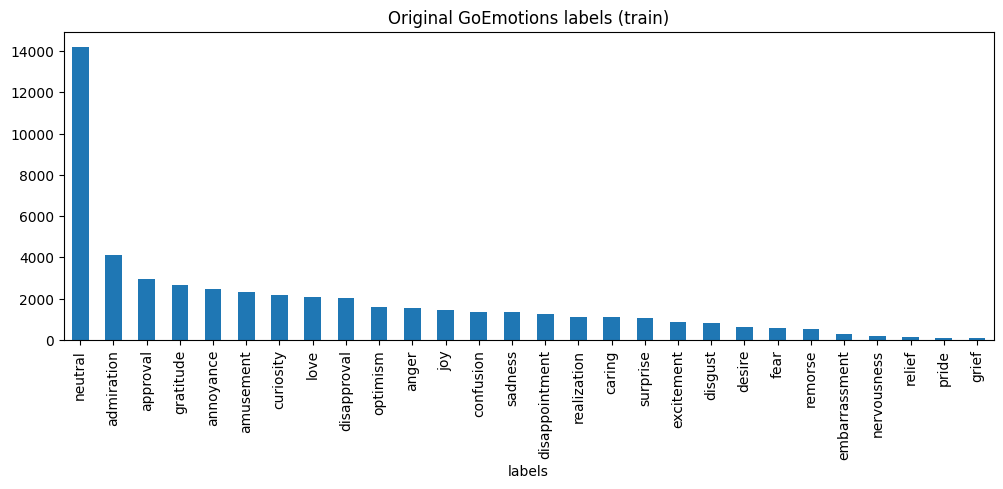

In [33]:
plt.figure(figsize=(12, 4))
all_labels.value_counts().plot(kind="bar")
plt.title("Original GoEmotions labels (train)")
plt.show()

count    43410.000000
mean        12.840175
std          6.701597
min          1.000000
25%          7.000000
50%         12.000000
75%         18.000000
max         33.000000
Name: length, dtype: float64


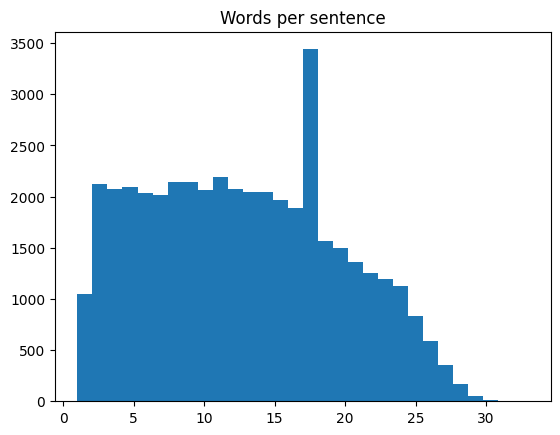

In [34]:
# sentence length
train_df["length"] = train_df["text"].apply(lambda t: len(t.split()))
print(train_df["length"].describe())

plt.hist(train_df["length"], bins=30)
plt.title("Words per sentence")
plt.show()

In [35]:
# some samples
for i in range(5):
    print(train_df["text"][i], "->", [names[j] for j in train_df["labels"][i]])

My favourite food is anything I didn't have to cook myself. -> ['neutral']
Now if he does off himself, everyone will think hes having a laugh screwing with people instead of actually dead -> ['neutral']
WHY THE FUCK IS BAYLESS ISOING -> ['anger']
To make her feel threatened -> ['fear']
Dirty Southern Wankers -> ['annoyance']


## 4. Map the labels to 6 emotions

In [36]:
# Ekman mapping
ekman = {
    "anger": ["anger", "annoyance", "disapproval"],
    "disgust": ["disgust"],
    "fear": ["fear", "nervousness"],
    "joy": ["joy", "amusement", "approval", "excitement", "gratitude", "love",
            "optimism", "relief", "pride", "admiration", "desire", "caring"],
    "sadness": ["sadness", "disappointment", "embarrassment", "grief", "remorse"],
    "surprise": ["surprise", "realization", "confusion", "curiosity"],
    "neutral": ["neutral"],
}

group_of = {}
for group, items in ekman.items():
    for item in items:
        group_of[item] = group

print(group_of)

{'anger': 'anger', 'annoyance': 'anger', 'disapproval': 'anger', 'disgust': 'disgust', 'fear': 'fear', 'nervousness': 'fear', 'joy': 'joy', 'amusement': 'joy', 'approval': 'joy', 'excitement': 'joy', 'gratitude': 'joy', 'love': 'joy', 'optimism': 'joy', 'relief': 'joy', 'pride': 'joy', 'admiration': 'joy', 'desire': 'joy', 'caring': 'joy', 'sadness': 'sadness', 'disappointment': 'sadness', 'embarrassment': 'sadness', 'grief': 'sadness', 'remorse': 'sadness', 'surprise': 'surprise', 'realization': 'surprise', 'confusion': 'surprise', 'curiosity': 'surprise', 'neutral': 'neutral'}


In [37]:
emotions = ["joy", "sadness", "anger", "fear", "surprise", "disgust"]
label2id = {e: i for i, e in enumerate(emotions)}
id2label = {i: e for i, e in enumerate(emotions)}

def map_label(label_ids):
    groups = set(group_of[names[i]] for i in label_ids)
    groups.discard("neutral")
    # keep the sentence only if it has exactly one emotion
    if len(groups) == 1:
        return groups.pop()
    return None

for df in [train_df, val_df, test_df]:
    df["emotion"] = df["labels"].apply(map_label)

In [38]:
train_df = train_df.dropna(subset=["emotion"]).reset_index(drop=True)
val_df = val_df.dropna(subset=["emotion"]).reset_index(drop=True)
test_df = test_df.dropna(subset=["emotion"]).reset_index(drop=True)

for df in [train_df, val_df, test_df]:
    df["label"] = df["emotion"].map(label2id)

print(train_df.shape, val_df.shape, test_df.shape)
print(train_df["emotion"].value_counts())

(28104, 6) (3527, 5) (3539, 5)
emotion
joy         15809
anger        4590
surprise     4160
sadness      2455
fear          566
disgust       524
Name: count, dtype: int64


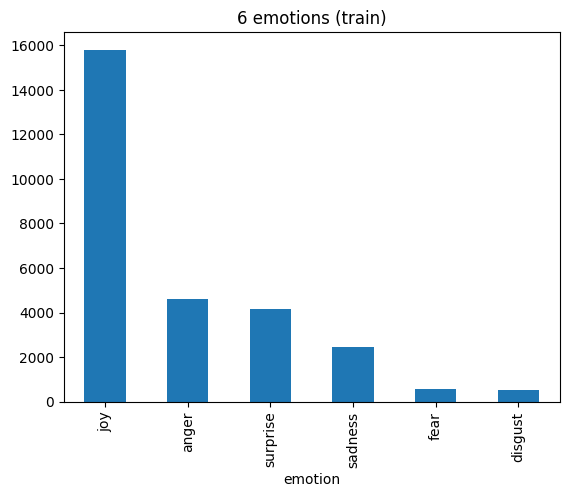

In [39]:
train_df["emotion"].value_counts().plot(kind="bar")
plt.title("6 emotions (train)")
plt.show()

## 5. Clean the text

In [40]:
def clean_text(text):
    text = text.lower()
    text = re.sub(r"\[.*?\]", " ", text)
    text = re.sub(r"[^a-z\s]", " ", text)
    text = re.sub(r"\s+", " ", text).strip()
    return text

print(train_df["text"][0])
print(clean_text(train_df["text"][0]))

WHY THE FUCK IS BAYLESS ISOING
why the fuck is bayless isoing


In [41]:
for df in [train_df, val_df, test_df]:
    df["clean"] = df["text"].apply(clean_text)

train_df[["text", "clean", "emotion"]].head()

,text,clean,emotion
0,WHY THE FUCK IS BAYLESS ISOING,why the fuck is bayless isoing,anger
1,To make her feel threatened,to make her feel threatened,fear
2,Dirty Southern Wankers,dirty southern wankers,anger
3,OmG pEyToN iSn'T gOoD eNoUgH tO hElP uS iN tHe...,omg peyton isn t good enough to help us in the...,surprise
4,Yes I heard abt the f bombs! That has to be wh...,yes i heard abt the f bombs that has to be why...,joy


## 6. Tokenize and pad

In [42]:
max_words = 20000
max_len = 40

tokenizer = Tokenizer(num_words=max_words, oov_token="<OOV>")
tokenizer.fit_on_texts(train_df["clean"])

print(len(tokenizer.word_index))

19667


In [43]:
def to_padded(texts):
    seq = tokenizer.texts_to_sequences(texts)
    return pad_sequences(seq, maxlen=max_len, padding="post", truncating="post")

X_train = to_padded(train_df["clean"])
X_val = to_padded(val_df["clean"])
X_test = to_padded(test_df["clean"])

y_train = train_df["label"].values
y_val = val_df["label"].values
y_test = test_df["label"].values

print(X_train.shape, X_val.shape, X_test.shape)
print(X_train[0])

(28104, 40) (3527, 40) (3539, 40)
[  87    3  158   10 6873 9645    0    0    0    0    0    0    0    0
    0    0    0    0    0    0    0    0    0    0    0    0    0    0
    0    0    0    0    0    0    0    0    0    0    0    0]


## 7. GloVe embeddings

In [44]:
import gensim.downloader as api

glove = api.load("glove-wiki-gigaword-100")
embed_dim = 100
print(glove["happy"][:5])

[-0.090436  0.19636   0.29474  -0.47706  -0.80436 ]


In [45]:
vocab_size = min(max_words, len(tokenizer.word_index) + 1)
embedding_matrix = np.zeros((vocab_size, embed_dim))

found = 0
for word, i in tokenizer.word_index.items():
    if i >= vocab_size:
        continue
    if word in glove:
        embedding_matrix[i] = glove[word]
        found += 1

print("words found in GloVe:", found, "from", vocab_size)

words found in GloVe: 17537 from 19668


In [46]:
# the data is not balanced, so we use class weights
weights = compute_class_weight("balanced", classes=np.arange(6), y=y_train)
class_weight = dict(enumerate(weights))
print(class_weight)

{0: np.float64(0.2962869251692074), 1: np.float64(1.9079429735234217), 2: np.float64(1.020479302832244), 3: np.float64(8.275618374558304), 4: np.float64(1.1259615384615385), 5: np.float64(8.938931297709924)}


## 8. Helper functions

In [47]:
results = {}

def train_model(model, epochs=15):
    model.compile(loss="sparse_categorical_crossentropy", optimizer="adam", metrics=["accuracy"])
    early = EarlyStopping(monitor="val_loss", patience=2, restore_best_weights=True)
    history = model.fit(X_train, y_train,
                        validation_data=(X_val, y_val),
                        epochs=epochs, batch_size=64,
                        class_weight=class_weight,
                        callbacks=[early])
    return history

def plot_history(history):
    plt.figure(figsize=(10, 4))
    plt.subplot(1, 2, 1)
    plt.plot(history.history["loss"], label="train")
    plt.plot(history.history["val_loss"], label="val")
    plt.title("Loss")
    plt.legend()
    plt.subplot(1, 2, 2)
    plt.plot(history.history["accuracy"], label="train")
    plt.plot(history.history["val_accuracy"], label="val")
    plt.title("Accuracy")
    plt.legend()
    plt.show()

In [48]:
def evaluate(y_true, y_pred, name):
    acc = accuracy_score(y_true, y_pred)
    f1 = f1_score(y_true, y_pred, average="macro")
    print(name)
    print("Accuracy:", round(acc, 4))
    print("Macro F1:", round(f1, 4))
    print()
    print(classification_report(y_true, y_pred, target_names=emotions))

    cm = confusion_matrix(y_true, y_pred)
    plt.figure(figsize=(6, 5))
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=emotions, yticklabels=emotions)
    plt.xlabel("Predicted")
    plt.ylabel("True")
    plt.title("Confusion matrix - " + name)
    plt.show()

    results[name] = {"Accuracy": acc, "Macro F1": f1}

## 9. Model 1: LSTM

In [51]:
lstm_model = Sequential([
    Input(shape=(max_len,)),
    Embedding(
        vocab_size,
        embed_dim,
        embeddings_initializer=Constant(embedding_matrix),
        trainable=False,
        mask_zero=True
    ),
    LSTM(64, use_cudnn=False),
    Dropout(0.3),
    Dense(6, activation="softmax"),
])

lstm_model.summary()

Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding_2 (Embedding)         │ (None, 40, 100)        │     1,966,800 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_2 (LSTM)                   │ (None, 64)             │        42,240 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 6)              │           390 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,009,430 (7.67 MB)

 Trainable params: 42,630 (166.52 KB)

 Non-trainable params: 1,966,800 (7.50 MB)

In [52]:
history_lstm = train_model(lstm_model)

Epoch 1/15
440/440 ━━━━━━━━━━━━━━━━━━━━ 18s 19ms/step - accuracy: 0.4271 - loss: 1.5638 - val_accuracy: 0.5248 - val_loss: 1.3456
Epoch 2/15
440/440 ━━━━━━━━━━━━━━━━━━━━ 3s 6ms/step - accuracy: 0.5592 - loss: 1.2628 - val_accuracy: 0.5948 - val_loss: 1.1276
Epoch 3/15
440/440 ━━━━━━━━━━━━━━━━━━━━ 3s 6ms/step - accuracy: 0.5989 - loss: 1.1180 - val_accuracy: 0.6028 - val_loss: 1.1208
Epoch 4/15
440/440 ━━━━━━━━━━━━━━━━━━━━ 3s 6ms/step - accuracy: 0.6155 - loss: 1.0260 - val_accuracy: 0.6334 - val_loss: 1.0216
Epoch 5/15
440/440 ━━━━━━━━━━━━━━━━━━━━ 3s 8ms/step - accuracy: 0.6347 - loss: 0.9679 - val_accuracy: 0.6255 - val_loss: 1.0057
Epoch 6/15
440/440 ━━━━━━━━━━━━━━━━━━━━ 5s 7ms/step - accuracy: 0.6435 - loss: 0.9166 - val_accuracy: 0.5861 - val_loss: 1.1123
Epoch 7/15
440/440 ━━━━━━━━━━━━━━━━━━━━ 3s 6ms/step - accuracy: 0.6549 - loss: 0.8778 - val_accuracy: 0.6450 - val_loss: 0.9875
Epoch 8/15
440/440 ━━━━━━━━━━━━━━━━━━━━ 3s 7ms/step - accuracy: 0.6629 - loss: 0.8449 - val_accuracy: 

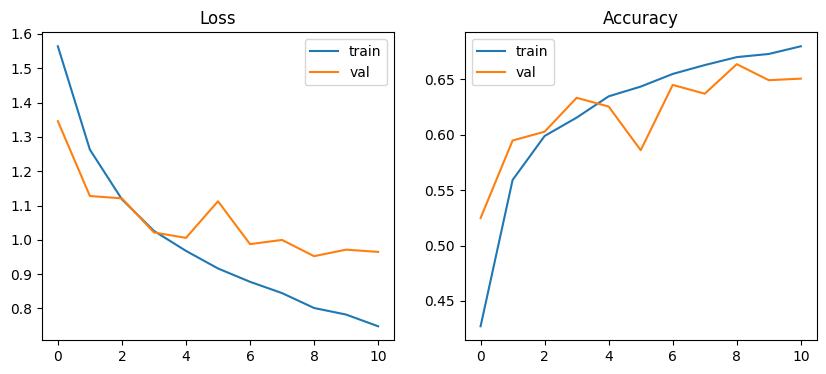

In [53]:
plot_history(history_lstm)

111/111 ━━━━━━━━━━━━━━━━━━━━ 3s 16ms/step
LSTM
Accuracy: 0.6589
Macro F1: 0.551

              precision    recall  f1-score   support

         joy       0.90      0.72      0.80      1937
     sadness       0.50      0.57      0.53       298
       anger       0.55      0.45      0.50       609
        fear       0.37      0.81      0.51        85
    surprise       0.46      0.69      0.55       533
     disgust       0.31      0.62      0.42        77

    accuracy                           0.66      3539
   macro avg       0.51      0.65      0.55      3539
weighted avg       0.72      0.66      0.67      3539



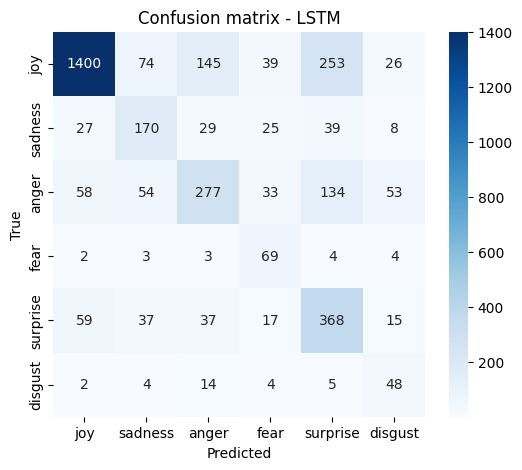

In [54]:
y_pred = np.argmax(lstm_model.predict(X_test), axis=1)
evaluate(y_test, y_pred, "LSTM")

## 10. Model 2: GRU

In [57]:
gru_model = Sequential([
    Input(shape=(max_len,)),
    Embedding(vocab_size, embed_dim, embeddings_initializer=Constant(embedding_matrix), trainable=False, mask_zero=True),
    GRU(64, use_cudnn=False),
    Dropout(0.3),
    Dense(6, activation="softmax"),
])
gru_model.summary()

Model: "sequential_4"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding_4 (Embedding)         │ (None, 40, 100)        │     1,966,800 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ gru_1 (GRU)                     │ (None, 64)             │        31,872 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_4 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 6)              │           390 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,999,062 (7.63 MB)

 Trainable params: 32,262 (126.02 KB)

 Non-trainable params: 1,966,800 (7.50 MB)

In [58]:
history_gru = train_model(gru_model)

Epoch 1/15
440/440 ━━━━━━━━━━━━━━━━━━━━ 12s 16ms/step - accuracy: 0.4304 - loss: 1.5680 - val_accuracy: 0.5401 - val_loss: 1.2851
Epoch 2/15
440/440 ━━━━━━━━━━━━━━━━━━━━ 4s 7ms/step - accuracy: 0.5831 - loss: 1.1734 - val_accuracy: 0.6130 - val_loss: 1.1042
Epoch 3/15
440/440 ━━━━━━━━━━━━━━━━━━━━ 3s 7ms/step - accuracy: 0.6253 - loss: 1.0310 - val_accuracy: 0.6303 - val_loss: 1.0244
Epoch 4/15
440/440 ━━━━━━━━━━━━━━━━━━━━ 3s 7ms/step - accuracy: 0.6426 - loss: 0.9703 - val_accuracy: 0.6532 - val_loss: 0.9716
Epoch 5/15
440/440 ━━━━━━━━━━━━━━━━━━━━ 3s 7ms/step - accuracy: 0.6527 - loss: 0.9290 - val_accuracy: 0.6657 - val_loss: 0.9483
Epoch 6/15
440/440 ━━━━━━━━━━━━━━━━━━━━ 3s 7ms/step - accuracy: 0.6653 - loss: 0.8848 - val_accuracy: 0.6717 - val_loss: 0.9273
Epoch 7/15
440/440 ━━━━━━━━━━━━━━━━━━━━ 3s 7ms/step - accuracy: 0.6708 - loss: 0.8529 - val_accuracy: 0.6776 - val_loss: 0.9098
Epoch 8/15
440/440 ━━━━━━━━━━━━━━━━━━━━ 3s 7ms/step - accuracy: 0.6800 - loss: 0.8195 - val_accuracy: 

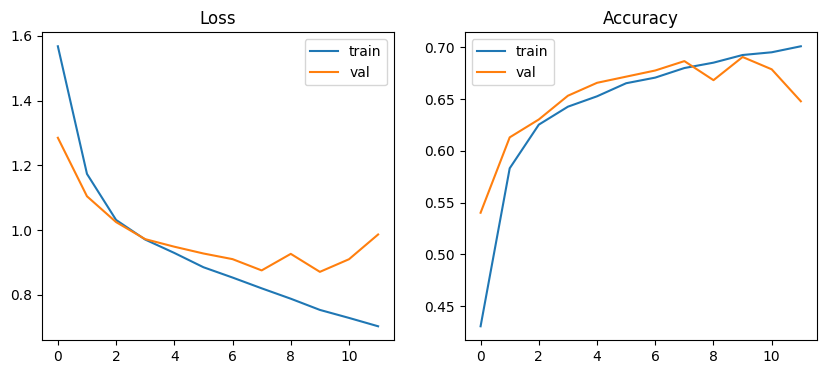

In [59]:
plot_history(history_gru)

111/111 ━━━━━━━━━━━━━━━━━━━━ 2s 11ms/step
GRU
Accuracy: 0.6731
Macro F1: 0.5878

              precision    recall  f1-score   support

         joy       0.93      0.71      0.80      1937
     sadness       0.49      0.61      0.54       298
       anger       0.52      0.59      0.56       609
        fear       0.60      0.64      0.62        85
    surprise       0.47      0.68      0.56       533
     disgust       0.35      0.64      0.45        77

    accuracy                           0.67      3539
   macro avg       0.56      0.64      0.59      3539
weighted avg       0.73      0.67      0.69      3539



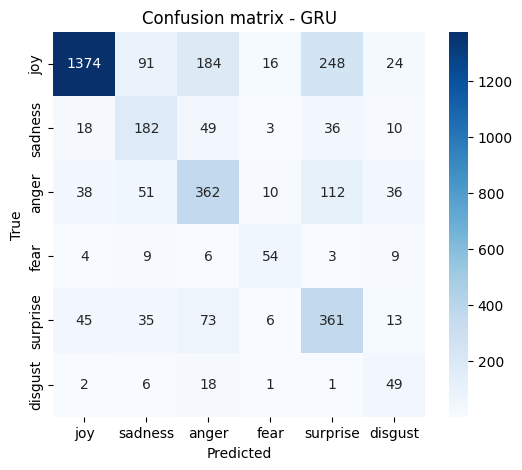

In [60]:
y_pred = np.argmax(gru_model.predict(X_test), axis=1)
evaluate(y_test, y_pred, "GRU")

## 11. Model 3: BiLSTM + Attention

In [61]:
# attention layer: gives a score for every word, then a weighted sum of the hidden states
class Attention(Layer):
    def __init__(self, units=64, **kwargs):
        super().__init__(**kwargs)
        self.units = units
        self.supports_masking = True
        self.dense1 = Dense(units, activation="tanh")
        self.dense2 = Dense(1)

    def call(self, x, mask=None):
        score = self.dense2(self.dense1(x))
        if mask is not None:
            mask = tf.cast(mask, tf.float32)
            score = score + (1.0 - tf.expand_dims(mask, -1)) * -1e9
        weights = tf.nn.softmax(score, axis=1)
        context = tf.reduce_sum(weights * x, axis=1)
        return context, weights

    def compute_mask(self, inputs, mask=None):
        return None

In [64]:
inputs = Input(shape=(max_len,))
x = Embedding(vocab_size, embed_dim, embeddings_initializer=Constant(embedding_matrix), trainable=False, mask_zero=True)(inputs)
x = Bidirectional(
    LSTM(64, return_sequences=True, use_cudnn=False)
)(x)
context, att_weights = Attention()(x)
context = Dropout(0.3)(context)
outputs = Dense(6, activation="softmax")(context)

att_model = Model(inputs, outputs)
# second model gives the attention weights (same layers)
weights_model = Model(inputs, att_weights)

att_model.summary()

Model: "functional_7"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer_6       │ (None, 40)        │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ embedding_6         │ (None, 40, 100)   │  1,966,800 │ input_layer_6[0]… │
│ (Embedding)         │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ not_equal_6         │ (None, 40)        │          0 │ input_layer_6[0]… │
│ (NotEqual)          │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ bidirectional_1     │ (None, 40, 128)   │     84,480 │ embedding_6[0][0… │
│ (Bidirectional)     │                   │            │ not_equal_6[0][0] │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ attention_1         │ [(None, 128),     │      8,321 │ bidirectional_1[… │
│ (Attention)         │ (None, 40, 1)]    │            │ not_equal_6[0][0] │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_6 (Dropout) │ (None, 128)       │          0 │ attention_1[0][0] │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_10 (Dense)    │ (None, 6)         │        774 │ dropout_6[0][0]   │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 2,060,375 (7.86 MB)

 Trainable params: 93,575 (365.53 KB)

 Non-trainable params: 1,966,800 (7.50 MB)

In [65]:
history_att = train_model(att_model)

Epoch 1/15
440/440 ━━━━━━━━━━━━━━━━━━━━ 83s 172ms/step - accuracy: 0.4939 - loss: 1.3680 - val_accuracy: 0.6076 - val_loss: 1.1286
Epoch 2/15
440/440 ━━━━━━━━━━━━━━━━━━━━ 77s 175ms/step - accuracy: 0.6259 - loss: 1.0445 - val_accuracy: 0.6660 - val_loss: 0.9530
Epoch 3/15
440/440 ━━━━━━━━━━━━━━━━━━━━ 80s 171ms/step - accuracy: 0.6499 - loss: 0.9591 - val_accuracy: 0.6578 - val_loss: 0.9535
Epoch 4/15
440/440 ━━━━━━━━━━━━━━━━━━━━ 74s 168ms/step - accuracy: 0.6607 - loss: 0.9112 - val_accuracy: 0.6538 - val_loss: 0.9563


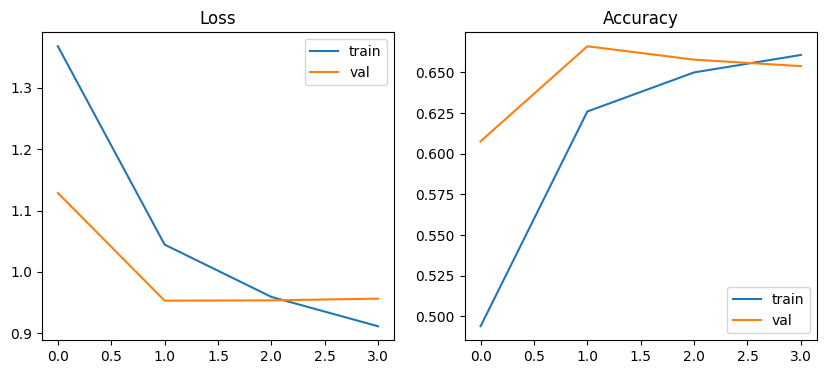

In [66]:
plot_history(history_att)

111/111 ━━━━━━━━━━━━━━━━━━━━ 5s 43ms/step
BiLSTM + Attention
Accuracy: 0.6612
Macro F1: 0.5738

              precision    recall  f1-score   support

         joy       0.90      0.72      0.80      1937
     sadness       0.58      0.55      0.56       298
       anger       0.53      0.51      0.52       609
        fear       0.46      0.78      0.58        85
    surprise       0.43      0.65      0.51       533
     disgust       0.34      0.71      0.46        77

    accuracy                           0.66      3539
   macro avg       0.54      0.65      0.57      3539
weighted avg       0.71      0.66      0.68      3539



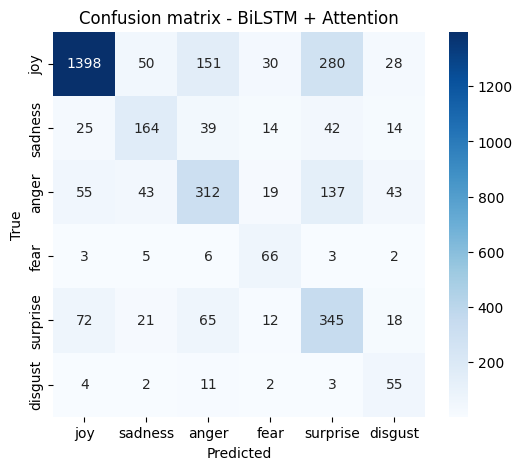

In [67]:
y_pred = np.argmax(att_model.predict(X_test), axis=1)
evaluate(y_test, y_pred, "BiLSTM + Attention")

## 12. Attention heatmaps

In [68]:
def show_attention(text):
    clean = clean_text(text)
    words = clean.split()[:max_len]
    padded = to_padded([clean])

    probs = att_model.predict(padded, verbose=0)[0]
    w = weights_model.predict(padded, verbose=0)[0, :, 0]
    w = w[:len(words)]

    pred = emotions[np.argmax(probs)]

    plt.figure(figsize=(max(6, len(words) * 0.8), 1.8))
    sns.heatmap(w.reshape(1, -1), annot=True, fmt=".2f", cmap="Reds",
                xticklabels=words, yticklabels=[""], cbar=False)
    plt.title("Prediction: " + pred + " (" + str(round(probs.max() * 100, 1)) + "%)")
    plt.xticks(rotation=45)
    plt.show()

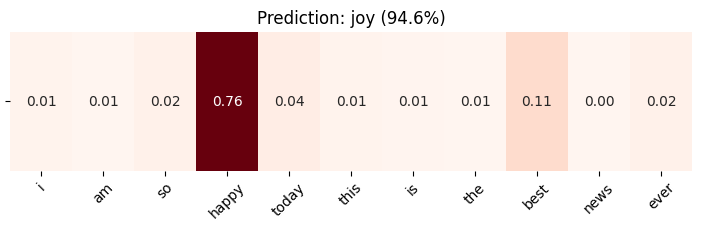

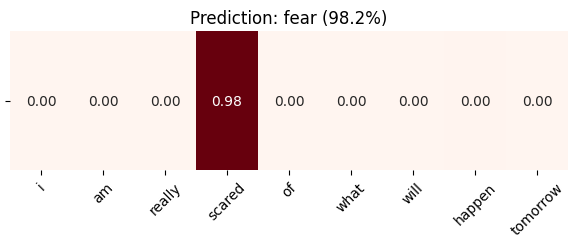

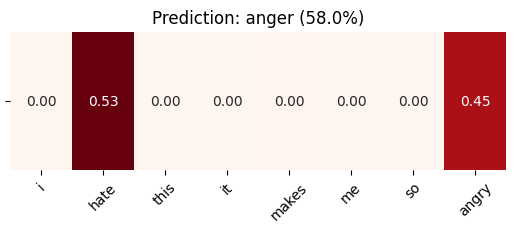

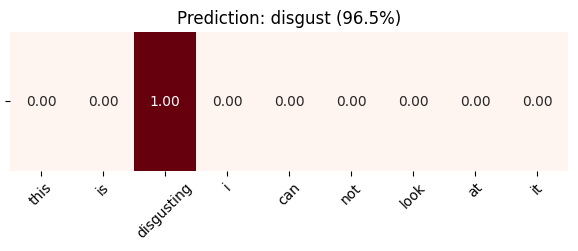

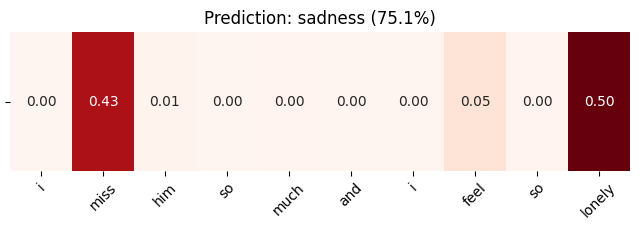

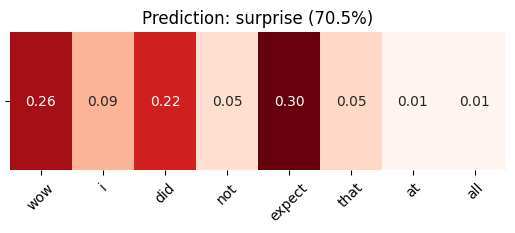

In [69]:
show_attention("I am so happy today, this is the best news ever")
show_attention("I am really scared of what will happen tomorrow")
show_attention("I hate this, it makes me so angry")
show_attention("This is disgusting, I can not look at it")
show_attention("I miss him so much and I feel so lonely")
show_attention("Wow I did not expect that at all")

## 13. Model 4: DistilBERT (HuggingFace Trainer)

In [70]:
from datasets import Dataset
from transformers import AutoTokenizer, AutoModelForSequenceClassification
from transformers import TrainingArguments, Trainer, DataCollatorWithPadding

model_name = "distilbert-base-uncased"
bert_tokenizer = AutoTokenizer.from_pretrained(model_name)

config.json:   0%|          | 0.00/483 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

In [71]:
# BERT uses the original text (no cleaning)
train_ds = Dataset.from_dict({"text": train_df["text"].tolist(), "label": y_train.tolist()})
val_ds = Dataset.from_dict({"text": val_df["text"].tolist(), "label": y_val.tolist()})
test_ds = Dataset.from_dict({"text": test_df["text"].tolist(), "label": y_test.tolist()})

def tokenize(batch):
    return bert_tokenizer(batch["text"], truncation=True, max_length=64)

train_ds = train_ds.map(tokenize, batched=True)
val_ds = val_ds.map(tokenize, batched=True)
test_ds = test_ds.map(tokenize, batched=True)

print(train_ds)

Map:   0%|          | 0/28104 [00:00<?, ? examples/s]

Map:   0%|          | 0/3527 [00:00<?, ? examples/s]

Map:   0%|          | 0/3539 [00:00<?, ? examples/s]

Dataset({
    features: ['text', 'label', 'input_ids', 'token_type_ids', 'attention_mask'],
    num_rows: 28104
})


In [72]:
bert_model = AutoModelForSequenceClassification.from_pretrained(
    model_name, num_labels=6, id2label=id2label, label2id=label2id)

model.safetensors: reconstructing file:   0%|          |  0.00B /  268MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertForSequenceClassification LOAD REPORT from: distilbert-base-uncased
Key                     | Status     | 
------------------------+------------+-
vocab_transform.bias    | UNEXPECTED | 
vocab_projector.bias    | UNEXPECTED | 
vocab_transform.weight  | UNEXPECTED | 
vocab_layer_norm.bias   | UNEXPECTED | 
vocab_layer_norm.weight | UNEXPECTED | 
pre_classifier.bias     | MISSING    | 
classifier.weight       | MISSING    | 
classifier.bias         | MISSING    | 
pre_classifier.weight   | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


In [73]:
def compute_metrics(eval_pred):
    logits, labels = eval_pred
    preds = np.argmax(logits, axis=1)
    return {"accuracy": accuracy_score(labels, preds),
            "f1": f1_score(labels, preds, average="macro")}

args = TrainingArguments(
    output_dir="results",
    eval_strategy="epoch",
    save_strategy="epoch",
    learning_rate=2e-5,
    per_device_train_batch_size=32,
    per_device_eval_batch_size=64,
    num_train_epochs=3,
    weight_decay=0.01,
    load_best_model_at_end=True,
    metric_for_best_model="f1",
    fp16=True,
    report_to="none",
)

trainer = Trainer(
    model=bert_model,
    args=args,
    train_dataset=train_ds,
    eval_dataset=val_ds,
    data_collator=DataCollatorWithPadding(bert_tokenizer),
    compute_metrics=compute_metrics,
)

In [74]:
trainer.train()

Epoch,Training Loss,Validation Loss,Accuracy,F1
1,0.742172,0.524334,0.824497,0.710057
2,0.453544,0.515412,0.826765,0.727290
3,0.369691,0.521411,0.831018,0.727078


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

TrainOutput(global_step=2637, training_loss=0.49476060661168364, metrics={'train_runtime': 156.7527, 'train_samples_per_second': 537.866, 'train_steps_per_second': 16.823, 'total_flos': 781714831542048.0, 'train_loss': 0.49476060661168364, 'epoch': 3.0})

DistilBERT
Accuracy: 0.8101
Macro F1: 0.7009

              precision    recall  f1-score   support

         joy       0.93      0.89      0.91      1937
     sadness       0.61      0.66      0.64       298
       anger       0.68      0.72      0.70       609
        fear       0.69      0.72      0.71        85
    surprise       0.74      0.75      0.75       533
     disgust       0.54      0.48      0.51        77

    accuracy                           0.81      3539
   macro avg       0.70      0.71      0.70      3539
weighted avg       0.82      0.81      0.81      3539



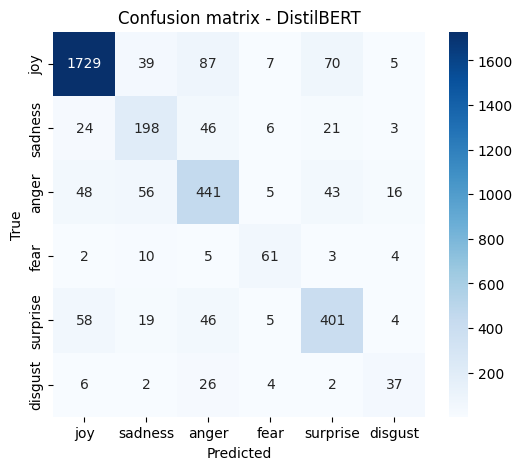

In [75]:
output = trainer.predict(test_ds)
y_pred = np.argmax(output.predictions, axis=1)
evaluate(y_test, y_pred, "DistilBERT")

In [76]:
trainer.save_model("emotion_distilbert")
bert_tokenizer.save_pretrained("emotion_distilbert")

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

('emotion_distilbert/tokenizer_config.json',
 'emotion_distilbert/tokenizer.json')

## 14. Compare the 4 models

In [77]:
comparison = pd.DataFrame(results).T
comparison = comparison.round(4)
comparison

,Accuracy,Macro F1
LSTM,0.6589,0.5510
GRU,0.6731,0.5878
BiLSTM + Attention,0.6612,0.5738
DistilBERT,0.8101,0.7009


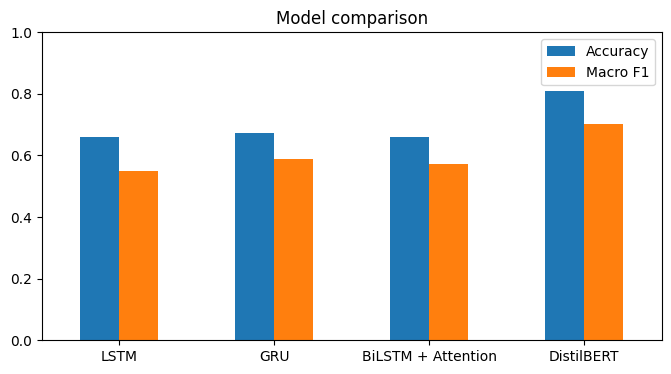

In [78]:
comparison.plot(kind="bar", figsize=(8, 4))
plt.title("Model comparison")
plt.ylim(0, 1)
plt.xticks(rotation=0)
plt.show()

## 15. Deployment (Gradio)

In [79]:
%%writefile app.py
import gradio as gr
import matplotlib.pyplot as plt
from transformers import pipeline

classifier = pipeline("text-classification", model="emotion_distilbert", top_k=None)

def predict(text):
    out = classifier(text)
    if isinstance(out[0], list):
        out = out[0]

    probs = {}
    for item in out:
        probs[item["label"]] = item["score"]

    top = max(probs, key=probs.get)
    result = top + " (" + str(round(probs[top] * 100, 1)) + "%)"

    fig, ax = plt.subplots(figsize=(6, 3))
    ax.bar(list(probs.keys()), list(probs.values()))
    ax.set_ylim(0, 1)
    ax.set_ylabel("Confidence")
    plt.close(fig)
    return result, fig

demo = gr.Interface(
    fn=predict,
    inputs=gr.Textbox(lines=3, label="Enter your text"),
    outputs=[gr.Textbox(label="Dominant emotion"), gr.Plot(label="Confidence for each emotion")],
    title="Emotion Classifier",
    examples=["I am so happy today!", "I am scared of tomorrow", "This makes me so angry"],
)

if __name__ == "__main__":
    demo.launch()

Writing app.py


In [80]:
# run the app (gives a public link)
from app import demo
demo.launch(share=True)

Loading weights:   0%|          | 0/104 [00:00<?, ?it/s]

Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://7f6684ca0086523238.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)
